In [68]:
import sys
print(sys.executable)

/Users/minnos/churn-exam/.venv/bin/python


In [69]:
import torch

In [70]:
import pandas as pd, sklearn, torch
print("pandas", pd.__version__, "| sklearn", sklearn.__version__, "| torch", torch.__version__)

df = pd.read_csv("../data/customer_churn_exam.csv")
df.shape

pandas 3.0.6 | sklearn 1.9.1 | torch 2.14.1


(1818, 20)

# Churn prediction – exam case
Observation → Evidence → Decision

## 0. Setup (imports, random_state = 42, paths)

In [71]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RANDOM_STATE = 42
DATA_PATH = "../data/customer_churn_exam.csv"
TARGET = "churned_30d"
pd.set_option("display.max_colwidth", None)
pd.set_option("display.max_columns", None)   # show all columns, not "..."
df_raw = pd.read_csv(DATA_PATH)



## 1. Problem framing

The organisation would like to know whether each customer will cancel their subscription within the next 30 days. Each row of the dataset represents a single customer at the snapshot date 2026-08-01. The features describe the customer's situation and behaviour up to that date (e.g. contract type, tenure, logins in the last 30 days, support tickets in the last 90 days).

The target is `churned_30d`, where 1 means the customer leaves within 30 days after the snapshot and 0 means they stay. Since the target has two classes, it is a binary classification problem. The column `days_until_churn` could suggest a regression problem, but it only exists for customers who have already churned, so it is not used (see section 2).

In practice, the model would be run on a regular basis, for example monthly, for all active customers. The prediction is made on the snapshot date, which gives a clear rule for the rest of the work: only information that is known on that date can be used as a feature.

The result would primarily be used by the customer-success team to prioritise which customers to contact, and by the CRM/marketing team to decide who should receive a retention offer, before they leave. Because the model is meant to decide who receives an offer, information about offers already sent cannot be used as input (see section 2). Since each contact costs time and money and the teams have limited capacity, the model's main task is to rank customers by churn risk rather than only answer yes or no. Where to draw the line for "contact" is therefore a business decision based on capacity and on the cost of the two error types: missing a churner (lost revenue) versus contacting a customer who would have stayed (wasted effort and discount).

## 2. Data understanding

### 2.1 Overview

In [72]:
print("Shape:", df_raw.shape)
df_raw.info()

Shape: (1818, 20)
<class 'pandas.DataFrame'>
RangeIndex: 1818 entries, 0 to 1817
Data columns (total 20 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   customer_id           1818 non-null   str    
 1   snapshot_date         1818 non-null   str    
 2   signup_date           1818 non-null   str    
 3   age                   1727 non-null   float64
 4   region                1770 non-null   str    
 5   contract_type         1818 non-null   str    
 6   payment_method        1791 non-null   str    
 7   acquisition_channel   1818 non-null   str    
 8   tenure_months         1818 non-null   int64  
 9   monthly_fee           1818 non-null   float64
 10  discount_percent      1818 non-null   float64
 11  support_tickets_90d   1818 non-null   int64  
 12  late_payments_12m     1818 non-null   int64  
 13  login_days_30d        1818 non-null   float64
 14  avg_session_minutes   1758 non-null   float64
 15  feature_usage_

In [73]:
df_raw.head()

,customer_id,snapshot_date,signup_date,age,region,contract_type,payment_method,acquisition_channel,tenure_months,monthly_fee,discount_percent,support_tickets_90d,late_payments_12m,login_days_30d,avg_session_minutes,feature_usage_score,nps_score,retention_offer_sent,days_until_churn,churned_30d
0,C101109,2026-08-01,2023-06-18,52.0,south,monthly,NaN,partner,37,341.82,2.1,2,2,28.0,21.5,66.3,8.6,0,NaN,0
1,C101036,2026-08-01,2025-03-28,55.0,stockholm,monthly,autogiro,partner,16,465.30,13.4,1,0,25.0,21.0,53.7,8.3,0,NaN,0
2,C101292,2026-08-01,2021-08-08,43.0,west,two_year,invoice,organic,59,152.64,5.6,0,1,7.0,10.7,45.8,7.7,0,NaN,0
3,C101102,2026-08-01,2020-03-18,32.0,stockholm,monthly,invoice,paid_search,76,428.20,16.5,2,5,14.0,16.6,58.9,7.8,0,NaN,0
4,C100971,2026-08-01,2025-07-02,25.0,stockholm,monthly,card,partner,12,389.07,0.0,0,0,14.0,22.1,NaN,6.3,1,8.0,1


In [74]:
df_raw.nunique().sort_values()

snapshot_date              1
churned_30d                2
retention_offer_sent       2
contract_type              3
payment_method             4
region                     5
acquisition_channel        5
late_payments_12m          7
support_tickets_90d       10
days_until_churn          30
login_days_30d            31
age                       58
tenure_months             69
nps_score                 75
discount_percent         311
avg_session_minutes      328
feature_usage_score      657
signup_date             1219
monthly_fee             1753
customer_id             1800
dtype: int64

**Observation:** The dataset has 1,818 rows and 20 columns: an ID (`customer_id`), two dates (`snapshot_date`, `signup_date`), four categorical features (`region`, `contract_type`, `payment_method`, `acquisition_channel`), numeric features about the customer's contract, payments and usage, and the target `churned_30d`.

**Evidence:** `snapshot_date` has only one unique value (2026-08-01). `customer_id` has 1,800 unique values for 1,818 rows.

**Decision:** `snapshot_date` carries no information and is dropped. Because all rows share one date, a time-based validation (training on older data, testing on newer) is not possible; this is a limitation (section 10). `customer_id` is an identifier, not a feature, and is dropped. The 18 extra rows are investigated in 2.3.

### 2.2 Target distribution 

,count,share
churned_30d,,
0,1488,0.818
1,330,0.182


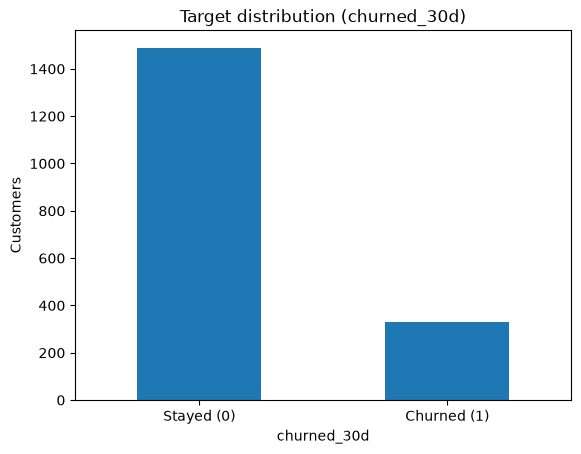

In [75]:
counts = df_raw[TARGET].value_counts()
shares = df_raw[TARGET].value_counts(normalize=True).round(3)
display(pd.DataFrame({"count": counts, "share": shares}))

counts.plot(kind="bar", title="Target distribution (churned_30d)")
plt.xticks([0, 1], ["Stayed (0)", "Churned (1)"], rotation=0)
plt.ylabel("Customers")
plt.show()

**Observation:** About 18% of customers churn (330 of 1,818); the classes are imbalanced.

**Evidence:** A model that always predicts "stays" would already reach ~82% accuracy while finding zero churners.

**Decision:** Accuracy is therefore misleading and is not the main metric; precision, recall, PR-AUC and the confusion matrix are used instead (section 6). All splits are stratified on the target so the ~18% churn share is the same in train, test and every CV fold.

### 2.3 Duplicates

In [76]:
print("Fully duplicated rows:", df_raw.duplicated().sum())
print("Duplicated customer_id:", df_raw["customer_id"].duplicated().sum())

Fully duplicated rows: 18
Duplicated customer_id: 18


In [77]:
# Show an example: one duplicated customer, both copies
dup_id = df_raw.loc[df_raw["customer_id"].duplicated(), "customer_id"].iloc[0]
df_raw[df_raw["customer_id"] == dup_id]

,customer_id,snapshot_date,signup_date,age,region,contract_type,payment_method,acquisition_channel,tenure_months,monthly_fee,discount_percent,support_tickets_90d,late_payments_12m,login_days_30d,avg_session_minutes,feature_usage_score,nps_score,retention_offer_sent,days_until_churn,churned_30d
275,C101116,2026-08-01,2025-01-26,44.0,south,monthly,card,organic,18,301.49,22.4,2,1,19.0,26.9,88.2,10.0,0,NaN,0
335,C101116,2026-08-01,2025-01-26,44.0,south,monthly,card,organic,18,301.49,22.4,2,1,19.0,26.9,88.2,10.0,0,NaN,0


In [78]:
df = df_raw.drop_duplicates().reset_index(drop=True)
print("Shape after removing duplicates:", df.shape)
print("Churn share after:", round(df[TARGET].mean(), 3))

Shape after removing duplicates: (1800, 20)
Churn share after: 0.179


**Observation:** 18 rows are exact duplicates. The number of duplicated `customer_id`s is also 18, so every duplicate is a complete copy of another row (not the same customer with conflicting values).

**Evidence:** `duplicated()` = 18 and `customer_id.duplicated()` = 18; the example above shows two identical rows.

**Decision:** Duplicates are removed **before** the train/test split (1,818 → 1,800 rows). Otherwise the same customer could end up in both training and test data, and the model would be tested on rows it has already seen — a form of data leakage that inflates the test score. The churn share is essentially unchanged (≈17.9%).

### 2.4 Missing values

In [79]:
missing = pd.DataFrame({
    "n_missing": df.isna().sum(),
    "pct_missing": (df.isna().mean() * 100).round(1),
})
missing[missing["n_missing"] > 0].sort_values("n_missing", ascending=False)

,n_missing,pct_missing
days_until_churn,1477,82.1
nps_score,140,7.8
age,91,5.1
avg_session_minutes,59,3.3
region,47,2.6
feature_usage_score,45,2.5
payment_method,26,1.4


In [80]:
# Is missingness random? Compare churn rate when value is missing vs present
rows = []
for col in df.columns[df.isna().any()]:
    is_missing = df[col].isna()
    rows.append({
        "column": col,
        "churn_if_present": round(df.loc[~is_missing, TARGET].mean(), 3),
        "churn_if_missing": round(df.loc[is_missing, TARGET].mean(), 3),
        "n_missing": is_missing.sum(),
    })
pd.DataFrame(rows).sort_values("n_missing", ascending=False)

,column,churn_if_present,churn_if_missing,n_missing
6,days_until_churn,1.000,0.000,1477
5,nps_score,0.180,0.171,140
0,age,0.178,0.198,91
3,avg_session_minutes,0.181,0.136,59
1,region,0.177,0.255,47
4,feature_usage_score,0.181,0.111,45
2,payment_method,0.178,0.269,26


**Observation:** Six features have missing values, all below 8% (largest: `nps_score`, 140 rows). `days_until_churn` is missing for 1,477 of 1,800 rows.

**Evidence:**
- `days_until_churn`: churn rate is 100% when the value is present and 0% when it is missing. The column only gets a value when the customer has churned, so its presence alone reveals the target → **leakage**, handled in 2.6.
- `region` (25.5% vs 17.7%) and `payment_method` (26.9% vs 17.8%) show higher churn when missing. However, the groups are small (47 and 26 customers); with n = 26 the standard error of a churn rate is ≈ 7.5 percentage points, so these differences are within ~1–1.5 standard errors and may be due to chance.
- `nps_score` and `age` show nearly the same churn rate whether missing or not, which suggests random missingness. `feature_usage_score` and `avg_session_minutes` are slightly lower when missing, but also based on small groups.

**Decision:**
- No rows are dropped; that would lose data and could bias the sample.
- Numeric features: median imputation (robust to outliers) plus a missing-indicator column, so the model *can* use missingness if it helps. Categorical features: missing values become their own category, `"missing"`. Whether the indicators actually help is tested in cross-validation, not assumed.
- All imputation happens **inside the scikit-learn pipeline**, fitted only on training data (section 3), to avoid leakage.

### 2.5 Plausibility & consistency

Step 1: Are the values within reasonable ranges?

In [81]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,1709.0,38.340550,12.168504,18.0,29.0000,38.000,47.000,78.00
tenure_months,1800.0,43.518333,19.804792,10.0,26.0000,43.000,60.000,78.00
monthly_fee,1800.0,396.531294,113.756074,99.0,323.7625,398.485,472.905,823.43
discount_percent,1800.0,10.757333,8.544965,0.0,3.4000,10.200,16.200,45.00
support_tickets_90d,1800.0,1.442222,1.217802,0.0,1.0000,1.000,2.000,9.00
late_payments_12m,1800.0,0.633889,0.841441,0.0,0.0000,0.000,1.000,6.00
login_days_30d,1800.0,13.853889,7.588447,0.0,8.0000,14.000,19.000,30.00
avg_session_minutes,1741.0,20.566858,7.038916,1.0,15.8000,20.500,25.100,47.20
feature_usage_score,1755.0,64.163077,19.062822,1.6,51.2000,64.500,77.400,100.00
nps_score,1660.0,7.686205,1.675062,1.5,6.5000,7.800,9.000,10.00


In [82]:
rules = {
    "age":                 (df["age"] < 16) | (df["age"] > 100),
    "login_days_30d":      (df["login_days_30d"] < 0) | (df["login_days_30d"] > 30),
    "nps_score":           (df["nps_score"] < 0) | (df["nps_score"] > 10),
    "discount_percent":    (df["discount_percent"] < 0) | (df["discount_percent"] > 100),
    "monthly_fee":         df["monthly_fee"] <= 0,
    "tenure_months":       df["tenure_months"] < 0,
    "support_tickets_90d": df["support_tickets_90d"] < 0,
}
pd.Series({col: int(mask.sum()) for col, mask in rules.items()}, name="n_impossible_values")

age                    0
login_days_30d         0
nps_score              0
discount_percent       0
monthly_fee            0
tenure_months          0
support_tickets_90d    0
Name: n_impossible_values, dtype: int64

Step 2: Values that are possible but odd

In [83]:
share_decimal = (df["nps_score"].dropna() % 1 != 0).mean()
print(f"Share of NPS scores with decimals: {share_decimal:.1%}")

Share of NPS scores with decimals: 78.9%


Step 3: Logic checks across columns

In [84]:
zero_login = df["login_days_30d"] == 0
contradiction = zero_login & (df["avg_session_minutes"] > 0)
print("Customers with 0 login days:", zero_login.sum())
print("...of which have avg_session_minutes > 0:", contradiction.sum())
print("Churn rate for 0-login customers:", round(df.loc[zero_login, TARGET].mean(), 3))
df.loc[contradiction, ["login_days_30d", "avg_session_minutes"]].describe()

Customers with 0 login days: 79
...of which have avg_session_minutes > 0: 79
Churn rate for 0-login customers: 0.354


,login_days_30d,avg_session_minutes
count,79.0,79.000000
mean,0.0,17.886076
std,0.0,6.875668
min,0.0,1.000000
25%,0.0,13.500000
50%,0.0,18.100000
75%,0.0,23.150000
max,0.0,30.200000


#### Evidence

Their session values look ordinary (1–30 min, median 18), not like placeholder values, which suggests the two columns are measured over different time windows.

In [85]:
months_calc = (pd.to_datetime(df["snapshot_date"]) - pd.to_datetime(df["signup_date"])).dt.days / 30.44
(df["tenure_months"] - months_calc.round()).value_counts()

-1.0    903
 0.0    897
Name: count, dtype: int64

Step 4: Apply the fix

In [86]:
# Rule-based fix: a customer with 0 login days cannot have an average session length.
df.loc[df["login_days_30d"] == 0, "avg_session_minutes"] = np.nan
print("avg_session_minutes missing after fix:", df["avg_session_minutes"].isna().sum())

avg_session_minutes missing after fix: 138


**Observation:** No values fall outside physically possible ranges (age 18–78, logins 0–30, NPS 0–10, no negative fees or counts). Three issues were found:
1. **Contradiction:** all 79 customers with `login_days_30d = 0` have `avg_session_minutes > 0` (≈18 min on average). Session time without any login is impossible.
2. **Unusual format:** 78.9% of `nps_score` values have decimals, although NPS is normally a whole number from 0 to 10.
3. **Redundancy:** `tenure_months` matches the months between `signup_date` and `snapshot_date` (differences of 0 or −1 from rounding).

**Evidence:** See the checks above. The 79 zero-login customers churn at 35% (about twice the average), so the zero itself looks like real low activity, not a data error. It is the session value that is inconsistent.

**Decision:**
1. `login_days_30d` is kept as is. For these 79 rows, `avg_session_minutes` is set to missing (later imputed in the pipeline, with a missing-indicator). This is a row-wise rule that learns nothing from other rows, so it is safe to apply before the split. A likely cause is that the two columns are measured over different time windows; this should be confirmed with the data owner.
2. `nps_score` is kept, but interpreted with care: it is probably an average or transformed score, not a single survey answer.
3. `signup_date` is dropped, since `tenure_months` carries the same information.
4. No outliers are removed: extreme values (e.g. 9 support tickets, a monthly fee of 823) are plausible for real customers, and the scaler and median imputation are robust enough for them.

 ### 2.6 Leakage Analysis

Test 1: days_until_churn

In [87]:
pd.crosstab(df["days_until_churn"].notna(), df[TARGET],
            rownames=["days_until_churn has a value"], colnames=["churned_30d"])

churned_30d,0,1
days_until_churn has a value,,
False,1477,0
True,0,323


Test 2: one feature at a time

In [88]:
from sklearn.metrics import roc_auc_score

rows = []
for col in df.select_dtypes("number").columns.drop([TARGET, "days_until_churn"]):
    filled = df[col].fillna(df[col].median())
    auc = roc_auc_score(df[TARGET], filled)
    rows.append({"feature": col,
                 "single_feature_auc": round(max(auc, 1 - auc), 3),
                 "direction": "higher → more churn" if auc >= 0.5 else "lower → more churn"})
pd.DataFrame(rows).sort_values("single_feature_auc", ascending=False)

,feature,single_feature_auc,direction
10,retention_offer_sent,0.770,higher → more churn
2,monthly_fee,0.648,higher → more churn
6,login_days_30d,0.647,lower → more churn
8,feature_usage_score,0.630,lower → more churn
4,support_tickets_90d,0.618,higher → more churn
9,nps_score,0.607,lower → more churn
1,tenure_months,0.552,lower → more churn
5,late_payments_12m,0.550,higher → more churn
7,avg_session_minutes,0.516,lower → more churn
3,discount_percent,0.509,lower → more churn


Test 3: a closer look at retention_offer_sent

In [89]:
display(pd.crosstab(df["retention_offer_sent"], df[TARGET], margins=True))
pd.crosstab(df["retention_offer_sent"], df[TARGET], normalize="index").round(3)

churned_30d,0,1,All
retention_offer_sent,,,
0,1368,125,1493
1,109,198,307
All,1477,323,1800


churned_30d,0,1
retention_offer_sent,,
0,0.916,0.084
1,0.355,0.645


**Observation:** Two columns contain information that would not be available, or should not be used, on the snapshot date.

**1. `days_until_churn` — direct target leakage.**
*Evidence:* The column has a value for exactly the 323 churners and is missing for all 1,477 non-churners. It describes something that happens *after* the snapshot.
*Decision:* Dropped. A model using it would simply learn "has a value → churn", which is impossible to use in practice.

**2. `retention_offer_sent` — probable leakage and an intervention variable.**
*Evidence:* On its own it reaches an AUC of 0.77, clearly above every legitimate behavioural feature (0.60–0.65). Customers who received an offer churned at 64.5%, compared with 8.4% for those who did not.
*Reasoning:* The offer is most likely sent *because* the company already noticed that the customer was about to leave (e.g. a cancellation request). Three problems follow:
- **Timing:** we do not know whether the offer was sent before or after the snapshot. If after, it is information from the future.
- **Circularity:** the model is meant to decide *who should receive* an offer (section 1). Using past offers as input means the model learns to copy earlier decisions instead of finding at-risk customers.
- **The offer affects the outcome:** the target for customers who got an offer is partly shaped by the offer itself, which mixes the customer's original risk with the effect of the intervention.

*Decision:* Excluded from the main model. To show the effect empirically, models are trained both with and without it in section 5. In a real project, I would confirm with the business **when** offers are sent relative to the snapshot date.

**Remaining assumption:** All other features are assumed to be measured up to the snapshot date (their names refer to past windows: `_30d`, `_90d`, `_12m`). This could not be verified in the data and is listed as a limitation; `nps_score` in particular could be from a survey taken after the snapshot.

### 2.7 Feature decisions (keep/drop table)

| Column | Decision | Reason |
|---|---|---|
| `customer_id` | Drop | Identifier, no predictive meaning |
| `snapshot_date` | Drop | Constant (one value) |
| `signup_date` | Drop | Redundant with `tenure_months` |
| `days_until_churn` | Drop | Target leakage (only exists for churners) |
| `retention_offer_sent` | Drop (tested in section 5) | Probable leakage and intervention variable |
| `churned_30d` | Target | |
| `region`, `contract_type`, `payment_method`, `acquisition_channel` | Keep (categorical) | Plausible churn drivers; one-hot encoded |
| `tenure_months`, `monthly_fee`, `discount_percent`, `support_tickets_90d`, `late_payments_12m`, `login_days_30d`, `feature_usage_score`, `nps_score` | Keep (numeric) | Plausible churn drivers, all known on the snapshot date |
| `avg_session_minutes` | Keep, after fix | Set to missing when `login_days_30d = 0` (see 2.5) |
| `age` | Keep for now (tested in section 5) | Weak signal (single-feature AUC ≈ 0.50); using age to target offers raises fairness concerns. Removed if performance does not drop. |

In [90]:
DROP_COLS = ["customer_id", "snapshot_date", "signup_date",
             "days_until_churn", "retention_offer_sent"]
CAT_COLS = ["region", "contract_type", "payment_method", "acquisition_channel"]
NUM_COLS = ["age", "tenure_months", "monthly_fee", "discount_percent",
            "support_tickets_90d", "late_payments_12m", "login_days_30d",
            "avg_session_minutes", "feature_usage_score", "nps_score"]

X = df.drop(columns=DROP_COLS + [TARGET])
y = df[TARGET]

assert set(X.columns) == set(CAT_COLS + NUM_COLS), "Column lists do not match X"
print("X:", X.shape, "| y churn share:", round(y.mean(), 3))

X: (1800, 14) | y churn share: 0.179


## 3. Data preparation (split, pipeline)

In [91]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (make_scorer, accuracy_score, roc_auc_score,
                             average_precision_score, precision_score,
                             recall_score, f1_score)

### 3.1 Train/test split

In [92]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print("Train:", X_train.shape, "| churn share:", round(y_train.mean(), 3))
print("Test: ", X_test.shape,  "| churn share:", round(y_test.mean(), 3))

Train: (1440, 14) | churn share: 0.179
Test:  (360, 14) | churn share: 0.181


The data is split into 80% training data (1,440 customers) and 20% test data (360 customers), stratified on the target so both sets have ≈18% churn. **The test set is not used again until the final evaluation in section 8.** All model comparison, tuning and threshold choice is done with cross-validation on the training data only. This way the test score is an honest estimate of performance on new customers.

### 3.2 Preprocessing pipeline

In [93]:
def make_preprocessor(num_cols=NUM_COLS, cat_cols=CAT_COLS):
    """Return a fresh, unfitted preprocessor (imputation, scaling, one-hot encoding)."""
    numeric = Pipeline([
        ("impute", SimpleImputer(strategy="median", add_indicator=True)),
        ("scale", StandardScaler()),
    ])
    categorical = Pipeline([
        ("impute", SimpleImputer(strategy="constant", fill_value="missing")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ])
    return ColumnTransformer([
        ("num", numeric, num_cols),
        ("cat", categorical, cat_cols),
    ])

### 3.3 Cross-validation setup

In [94]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

SCORING = {
    "accuracy":  "accuracy",
    "roc_auc":   "roc_auc",
    "pr_auc":    "average_precision",
    "precision": make_scorer(precision_score, zero_division=0),
    "recall":    "recall",
    "f1":        "f1",
}

def cv_evaluate(name, estimator, X_data=None):
    """Run 5-fold stratified CV on the training data and return mean scores."""
    X_data = X_train if X_data is None else X_data
    res = cross_validate(estimator, X_data, y_train, cv=cv,
                         scoring=SCORING, return_train_score=True)
    row = {"model": name}
    for metric in SCORING:
        row[metric] = res[f"test_{metric}"].mean()
    row["roc_auc_std"] = res["test_roc_auc"].std()
    row["train_roc_auc"] = res["train_roc_auc"].mean()
    return row

**Preprocessing:** numeric features are median-imputed (with missing-indicators) and standardised; categorical features get a `"missing"` category and are one-hot encoded (`handle_unknown="ignore"` so unseen categories in production do not crash the model). The preprocessing sits inside a scikit-learn `Pipeline` together with the model, so in every CV fold the imputer, scaler and encoder are fitted on the training folds only — the validation fold never influences them.

**Validation:** 5-fold stratified cross-validation on the training set, with the **same folds for every model** to make the comparison fair. For each model I report the mean and standard deviation across folds, and the training score to detect overfitting.

## 4. Baselines

A baseline answers the question: *does the model actually add anything compared with a very simple solution?* Two baselines are used:
1. **Majority class**: always predicts "stays". This is the minimum any model must beat.
2. **Business rule**: flags customers with a *monthly contract* who logged in on *fewer than 10 of the last 30 days*. This represents what a retention manager could do by hand without ML, and is a more demanding and more honest yardstick.

In [95]:
dummy = Pipeline([("pre", make_preprocessor()),
                  ("clf", DummyClassifier(strategy="most_frequent"))])
results.append(cv_evaluate("Baseline: majority class", dummy))
pd.DataFrame(results).round(3)

,model,accuracy,roc_auc,pr_auc,precision,recall,f1,roc_auc_std,train_roc_auc
0,Baseline: majority class,0.821,0.500,0.179,0.000,0.000,0.000,0.000,0.500
1,Baseline: business rule,0.784,0.618,0.255,0.390,0.360,0.373,0.015,NaN
2,Baseline: majority class,0.821,0.500,0.179,0.000,0.000,0.000,0.000,0.500
3,Baseline: business rule,0.784,0.618,0.255,0.390,0.360,0.373,0.015,NaN
4,Logistic Regression,0.694,0.753,0.429,0.331,0.686,0.446,0.013,0.797
5,Random Forest,0.753,0.747,0.409,0.366,0.496,0.420,0.022,0.992
6,Gradient Boosting,0.722,0.720,0.372,0.332,0.539,0.410,0.016,0.952
7,Baseline: majority class,0.821,0.500,0.179,0.000,0.000,0.000,0.000,0.500


In [96]:
def business_rule(X_part):
    """Flag monthly-contract customers with low activity. No learning from data."""
    return ((X_part["contract_type"] == "monthly") &
            (X_part["login_days_30d"] < 10)).astype(int)

# Evaluate on the exact same validation folds as the ML models
fold_scores = []
for _, val_idx in cv.split(X_train, y_train):
    X_val, y_val = X_train.iloc[val_idx], y_train.iloc[val_idx]
    pred = business_rule(X_val)
    fold_scores.append({
        "accuracy":  accuracy_score(y_val, pred),
        "roc_auc":   roc_auc_score(y_val, pred),
        "pr_auc":    average_precision_score(y_val, pred),
        "precision": precision_score(y_val, pred, zero_division=0),
        "recall":    recall_score(y_val, pred),
        "f1":        f1_score(y_val, pred),
    })
fold_df = pd.DataFrame(fold_scores)
rule_row = {"model": "Baseline: business rule", **fold_df.mean().to_dict(),
            "roc_auc_std": fold_df["roc_auc"].std(), "train_roc_auc": np.nan}
results.append(rule_row)

print("Share of customers flagged by the rule:", round(business_rule(X_train).mean(), 3))
pd.DataFrame(results).round(3)

Share of customers flagged by the rule: 0.166


,model,accuracy,roc_auc,pr_auc,precision,recall,f1,roc_auc_std,train_roc_auc
0,Baseline: majority class,0.821,0.500,0.179,0.000,0.000,0.000,0.000,0.500
1,Baseline: business rule,0.784,0.618,0.255,0.390,0.360,0.373,0.015,NaN
2,Baseline: majority class,0.821,0.500,0.179,0.000,0.000,0.000,0.000,0.500
3,Baseline: business rule,0.784,0.618,0.255,0.390,0.360,0.373,0.015,NaN
4,Logistic Regression,0.694,0.753,0.429,0.331,0.686,0.446,0.013,0.797
5,Random Forest,0.753,0.747,0.409,0.366,0.496,0.420,0.022,0.992
6,Gradient Boosting,0.722,0.720,0.372,0.332,0.539,0.410,0.016,0.952
7,Baseline: majority class,0.821,0.500,0.179,0.000,0.000,0.000,0.000,0.500
8,Baseline: business rule,0.784,0.618,0.255,0.390,0.360,0.373,0.015,NaN


**Observation:** The majority-class baseline reaches 82.1% accuracy but has 0% recall: it never finds a single churner. This confirms that accuracy is a misleading metric here.

The business rule has *lower* accuracy (78.4%) but is far more useful: it flags ~17% of customers, finds 36% of churners, and 39% of the flagged customers actually churn (vs 18% at random). Its ROC-AUC is 0.62 and PR-AUC 0.26.

**Decision:** The ML models must beat the **business rule**, not just the majority class, to be worth their extra complexity. Main comparison metrics: PR-AUC and ROC-AUC (how well the model ranks customers), plus precision and recall.

## 5. Models & cross-validation comparison

### 5.1 Model comparison

Three models with different strengths are compared, all with the same preprocessing and the same CV folds:

- **Logistic Regression**: a linear model. Simple, fast, interpretable (each feature gets a coefficient), and works well on small tabular datasets.
- **Random Forest**: many decision trees on random subsets of data and features, averaged. Captures non-linear effects and interactions.
- **Histogram Gradient Boosting**: trees built one after another, each correcting the errors of the previous ones. Often the strongest model family on tabular data.

All three use `class_weight="balanced"`, so mistakes on the rare churn class count more during training.

In [97]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

def make_models():
    return {
        "Logistic Regression": LogisticRegression(class_weight="balanced", max_iter=2000),
        "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                                                class_weight="balanced",
                                                random_state=RANDOM_STATE, n_jobs=-1),
        "Gradient Boosting": HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05,
                                                            max_iter=200, class_weight="balanced",
                                                            random_state=RANDOM_STATE),
    }

for name, model in make_models().items():
    pipe = Pipeline([("pre", make_preprocessor()), ("clf", model)])
    results.append(cv_evaluate(name, pipe))

results_df = pd.DataFrame(results).drop_duplicates("model", keep="last").reset_index(drop=True).round(3)
results_df

,model,accuracy,roc_auc,pr_auc,precision,recall,f1,roc_auc_std,train_roc_auc
0,Baseline: majority class,0.821,0.500,0.179,0.000,0.000,0.000,0.000,0.500
1,Baseline: business rule,0.784,0.618,0.255,0.390,0.360,0.373,0.015,NaN
2,Logistic Regression,0.694,0.753,0.429,0.331,0.686,0.446,0.013,0.797
3,Random Forest,0.753,0.747,0.409,0.366,0.496,0.420,0.022,0.992
4,Gradient Boosting,0.722,0.720,0.372,0.332,0.539,0.410,0.016,0.952


**Observation:**
- All three ML models clearly beat both baselines on the ranking metrics (ROC-AUC 0.72–0.75 vs 0.62 for the business rule; PR-AUC 0.37–0.43 vs 0.26).
- **Logistic Regression is best** on ROC-AUC (0.753), PR-AUC (0.429), recall (0.686) and F1 (0.446).
- **The tree models overfit:** Random Forest scores 0.992 on the training folds but 0.747 on validation (gap 0.25); Gradient Boosting 0.952 vs 0.720 (gap 0.23). Logistic Regression has a small gap (0.797 vs 0.753) and the lowest fold-to-fold variation (std 0.013).

**Interpretation:** With ~1,400 training rows and mostly monotonic relationships (fewer logins → more risk, higher fee → more risk), a linear model captures the signal without memorising noise. The extra flexibility of the tree models is not rewarded on this data.

*Note:* accuracy, precision and recall here use the default threshold of 0.5. With `class_weight="balanced"`, Logistic Regression flags many customers, giving high recall but lower accuracy. The threshold is chosen deliberately in section 6, so these three metrics should not be compared directly yet. The ranking metrics (ROC-AUC, PR-AUC) are the fair comparison.

### 5.2 Hyperparameter tuning

In [98]:
from sklearn.model_selection import GridSearchCV

param_grids = {
    "Logistic Regression": {"clf__C": [0.01, 0.1, 1, 10]},
    "Random Forest": {"clf__min_samples_leaf": [5, 20, 50], "clf__max_depth": [None, 5]},
    "Gradient Boosting": {"clf__max_depth": [2, 3], "clf__learning_rate": [0.03, 0.1],
                          "clf__max_iter": [100, 300]},
}

tuning_rows = []
for name, model in make_models().items():
    pipe = Pipeline([("pre", make_preprocessor()), ("clf", model)])
    search = GridSearchCV(pipe, param_grids[name], cv=cv, scoring="average_precision")
    search.fit(X_train, y_train)
    tuning_rows.append({"model": name,
                        "best_params": search.best_params_,
                        "best_cv_pr_auc": round(search.best_score_, 3)})
pd.DataFrame(tuning_rows)

,model,best_params,best_cv_pr_auc
0,Logistic Regression,{'clf__C': 0.01},0.431
1,Random Forest,"{'clf__max_depth': None, 'clf__min_samples_leaf': 5}",0.409
2,Gradient Boosting,"{'clf__learning_rate': 0.03, 'clf__max_depth': 2, 'clf__max_iter': 300}",0.397


Tuning was done with `GridSearchCV` on the same CV folds, optimising PR-AUC. It does **not** change the ranking:
- **Logistic Regression** is almost insensitive to the regularisation strength `C` (PR-AUC 0.427–0.431; best `C = 0.01`, 0.431). The model is already simple enough not to overfit.
- **Random Forest**'s best setting (`min_samples_leaf = 5`, no depth limit, PR-AUC 0.409) is the one already used in 5.1.
- **Gradient Boosting**'s best setting (`max_depth = 2`, `learning_rate = 0.03`, 300 iterations, PR-AUC 0.397) is still below Logistic Regression. It also chose the *shallowest* trees and the *slowest* learning rate, i.e. the least flexible option, which suggests the data does not reward complexity.

The gap is therefore not caused by poor configuration of the tree models but by the data: with ~1,400 rows and mostly monotonic relationships, the extra flexibility of trees mainly fits noise.

*Note:* scores from the same folds used for tuning are slightly optimistic. Since tuning changed nothing, this does not affect the conclusion, and the final model is evaluated on the untouched test set in section 8.

### 5.3 Leakage experiment: retention_offer_sent

In [99]:
X_train_offer = X_train.join(df["retention_offer_sent"])
num_with_offer = NUM_COLS + ["retention_offer_sent"]

leak_rows = []
for name, model in make_models().items():
    without = cv_evaluate(name, Pipeline([("pre", make_preprocessor()), ("clf", model)]))
    with_offer = cv_evaluate(name, Pipeline([("pre", make_preprocessor(num_with_offer)),
                                             ("clf", make_models()[name])]),
                             X_data=X_train_offer)
    leak_rows.append({"model": name,
                      "roc_auc_without": without["roc_auc"], "roc_auc_with": with_offer["roc_auc"],
                      "pr_auc_without": without["pr_auc"], "pr_auc_with": with_offer["pr_auc"]})
leak_df = pd.DataFrame(leak_rows).round(3)
leak_df["pr_auc_gain"] = (leak_df["pr_auc_with"] - leak_df["pr_auc_without"]).round(3)
leak_df

,model,roc_auc_without,roc_auc_with,pr_auc_without,pr_auc_with,pr_auc_gain
0,Logistic Regression,0.753,0.859,0.429,0.676,0.247
1,Random Forest,0.747,0.852,0.409,0.663,0.254
2,Gradient Boosting,0.720,0.836,0.372,0.635,0.263


Adding `retention_offer_sent` raises ROC-AUC by ~0.10 and PR-AUC by ~0.25 for **every** model. One yes/no column adds more than all ten behavioural features together. This confirms the analysis in 2.6: the column most likely encodes that the company *already knew* the customer was leaving (the offer is a reaction), and it is the very decision the model is meant to support.

**Decision:** The column stays excluded. The higher score is not a better model; it is a model that would not work in production, because at prediction time the offer has either not been sent yet or is the output we are trying to produce. A score of ~0.75 that holds up in reality is worth more than a score of ~0.86 that does not.

### 5.4 Feature experiments: removing age, adding effective fee

In [100]:
NUM_NO_AGE = [c for c in NUM_COLS if c != "age"]
X_train_fe = X_train.assign(
    effective_fee=X_train["monthly_fee"] * (1 - X_train["discount_percent"] / 100))

experiments = [
    cv_evaluate("LogReg: all features (reference)",
                Pipeline([("pre", make_preprocessor()),
                          ("clf", LogisticRegression(class_weight="balanced", max_iter=2000))])),
    cv_evaluate("LogReg: without age",
                Pipeline([("pre", make_preprocessor(NUM_NO_AGE)),
                          ("clf", LogisticRegression(class_weight="balanced", max_iter=2000))]),
                X_data=X_train.drop(columns="age")),
    cv_evaluate("LogReg: + effective_fee",
                Pipeline([("pre", make_preprocessor(NUM_COLS + ["effective_fee"])),
                          ("clf", LogisticRegression(class_weight="balanced", max_iter=2000))]),
                X_data=X_train_fe),
]
pd.DataFrame(experiments).round(3)[["model", "roc_auc", "pr_auc", "recall", "roc_auc_std"]]

,model,roc_auc,pr_auc,recall,roc_auc_std
0,LogReg: all features (reference),0.753,0.429,0.686,0.013
1,LogReg: without age,0.752,0.422,0.679,0.013
2,LogReg: + effective_fee,0.752,0.429,0.686,0.013


**Removing `age`:** performance is essentially unchanged (ROC-AUC 0.753 → 0.752, PR-AUC 0.429 → 0.422, differences well within the fold-to-fold variation). Age carries almost no signal (single-feature AUC ≈ 0.50), and using age to decide who receives offers raises fairness and discrimination concerns. **Decision: `age` is removed from the final model.** Less personal data, same performance.

**Adding `effective_fee`** (monthly fee after discount): no improvement. The model already has both components. **Decision: not added**; extra features without benefit only add complexity.

### 5.5 Summary and choice of candidate

In [101]:
FINAL_NUM_COLS = NUM_NO_AGE

def make_final_model():
    return Pipeline([
        ("pre", make_preprocessor(FINAL_NUM_COLS)),
        ("clf", LogisticRegression(class_weight="balanced", max_iter=2000)),
    ])

X_train_final = X_train.drop(columns="age")
X_test_final = X_test.drop(columns="age")
print("Final feature count (before encoding):", X_train_final.shape[1])

Final feature count (before encoding): 13


### 5.5 Summary

| Criterion | Logistic Regression | Random Forest | Gradient Boosting |
|---|---|---|---|
| ROC-AUC / PR-AUC (CV) | **0.753 / 0.429** | 0.747 / 0.408 | 0.720 / 0.372 |
| Overfitting (train − val ROC-AUC) | **0.04** | 0.25 | 0.23 |
| Stability (std ROC-AUC) | **0.013** | 0.022 | 0.016 |
| Interpretability | **High** (coefficients) | Medium | Medium |
| Training cost | **Lowest** | Higher | Medium |

**Candidate model: Logistic Regression without `age`, without `retention_offer_sent`.** It is at least as good as the more complex models on every ranking metric, overfits least, is the most stable, and is the easiest to explain to the retention team. All ML models clearly beat the business rule (PR-AUC 0.43 vs 0.26).

The threshold (how many customers to flag) is chosen in section 6. The test set is still untouched.

## 6. Evaluation: threshold, confusion matrix, top-k, error analysis

## 7. Deep Learning (MLP) & Transfer Learning

## 8. Final test-set evaluation

## 9. Save model & input schema